Matplotlib is building the font cache; this may take a moment.


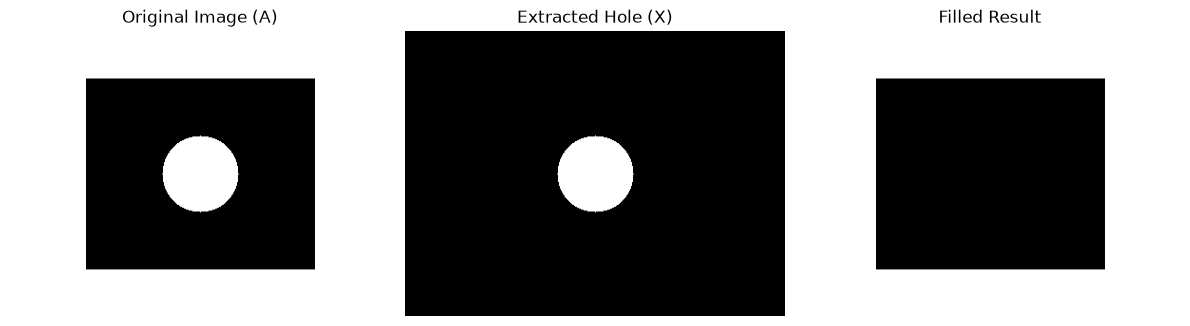

In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. إنشاء صورة اختبارية: خلفية بيضاء، مستطيل أسود، وفجوة بيضاء
h, w = 300, 400
A = np.full((h, w), 255, dtype=np.uint8)
cv2.rectangle(A, (80, 50), (320, 250), 0, -1)
cv2.circle(A, (200, 150), 40, 255, -1)

# 2. تحديد نقطة البداية (Seed Point)
X = np.zeros((h, w), dtype=np.uint8)
seed_point = (150, 200)
X[seed_point] = 255

# 3. عنصر الهيكلة (Structuring Element)
B = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))

# 4. التكرار حتى الثبات (Hole Detection / Filling)
while True:
    dilated = cv2.dilate(X, B)
    X_next = cv2.bitwise_and(dilated, A)
    if np.array_equal(X, X_next):
        break
    X = X_next

# 5. ملء الفجوة باللون الأسود داخل الصورة الأصلية
X_comp = cv2.bitwise_not(X)
result = cv2.bitwise_and(A, X_comp)

# 6. العرض بنظام الـ Subplots 
images = [A, X, result]
titles = ["Original Image (A)", "Extracted Hole (X)", "Filled Result"]

plt.figure(figsize=(12, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [2]:
#2--
import cv2
import numpy as np

# إنشاء الصورة (نفس الإعداد: خلفية بيضاء، مستطيل أسود، فجوة بيضاء)
h, w = 300, 400
A = np.full((h, w), 255, dtype=np.uint8)
cv2.rectangle(A, (80, 50), (320, 250), 0, -1)
cv2.circle(A, (200, 150), 40, 255, -1)

# نسخة للعمل عليها
result = A.copy()

# ملء الفجوة مباشرة بلون المستطيل (0 = أسود) انطلاقاً من نقطة داخلها
# ملاحظة: إحداثيات floodFill تأخذ (x, y) = (col, row)
seed_point = (200, 150)
cv2.floodFill(result, None, seed_point, 0)

# حفظ أو عرض النتيجة
cv2.imwrite("result_floodfill.png", result)

True